This notebook is used to visualize the circuit. 
Please run the run.sh first and save the result in the "../results/" directory.

In [8]:
import torch

import sys
import os
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(project_root)

from NeurFlow import Framework
from utils import visualize_chain_of_concepts
# from NeurFlow import Framework

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

directory = "../results_resnet50_custom/"
model_name = "resnet50_custom"
label = 0
tau = 16
path = os.path.join(directory, f"store_{model_name}_label{label}_tau{tau}.pth")

store = torch.load(path, map_location="cpu", weights_only=False)
FW = store["FW"]
layers = store["layers"]
del store

print(layers)


cuda
['fc', 'layer4.2', 'layer4.1', 'layer4.0', 'layer3.5', 'layer3.4', 'layer3.3', 'layer3.2', 'layer3.1', 'layer3.0', 'layer2.3']


First we cluster the concept vectors of each feature map. 
The print-out has the structure: {neuron_id: {semantic_group_id: concept_id}}

In [9]:
cluster_layer = 9       # the layer to cluster    
num_cluster = 3         # the number of clusters
num_top_vecs = 5        # number of representative vectors to show
dict_labels, _ = FW.cluster_concept_vectors(cluster_layer, num_cluster, num_top_vecs=num_top_vecs, max_n_clusters=100)
print(dict_labels)

{34: {1: 0}, 1607: {1: 0}, 1959: {}, 1225: {}, 810: {4: 1}, 1037: {}, 1678: {}, 655: {0: 2}, 463: {}, 82: {}, 1234: {0: 2}, 114: {}, 1846: {0: 2, 1: 0}, 1591: {0: 2, 1: 0}, 473: {2: 1}, 189: {0: 2, 1: 0}}


We visualize the concept using concept_id (vis_label).

Feature map: 810
Label: 4


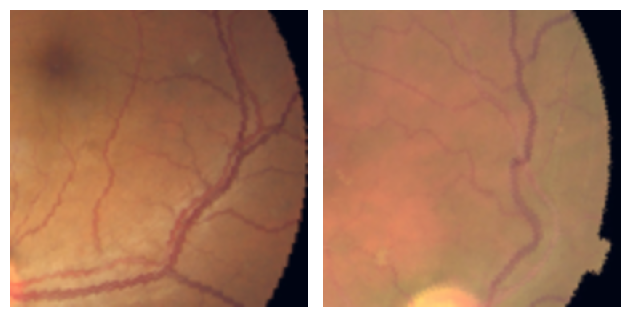

Feature map: 473
Label: 2


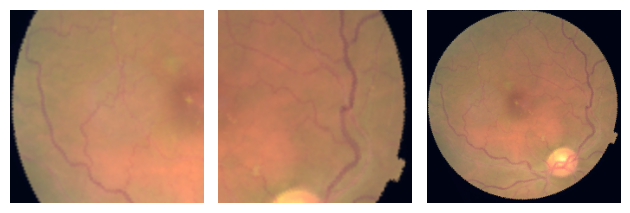

{810: 4, 473: 2}

In [10]:
vis_label = 1           # the cluster to visualize
num_vis = 5             # the number of examples to visualize
FW.visualize_cluster_concept_vectors(cluster_layer, vis_label, dict_labels, num_vis, num_top_images=5)

We can visualize all concepts.
Each concept has "num_vis" showed examples.

0
Feature map: 34
Label: 1


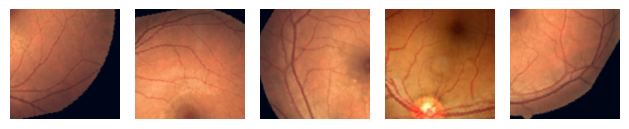

Feature map: 1607
Label: 1


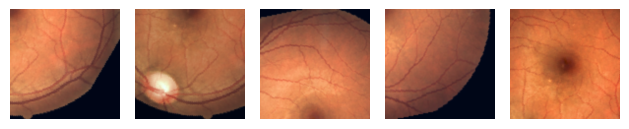

Feature map: 1846
Label: 1


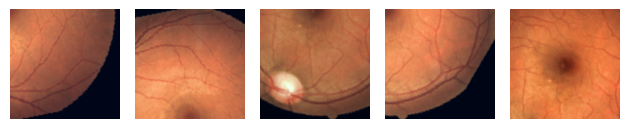

Feature map: 1591
Label: 1


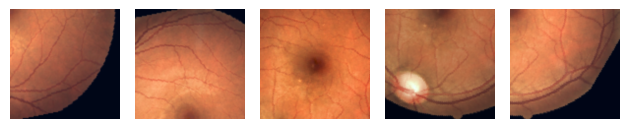

Feature map: 189
Label: 1


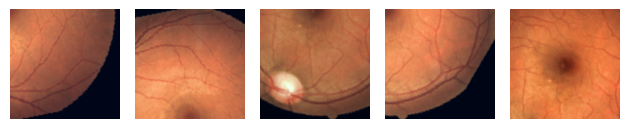

1
Feature map: 810
Label: 4


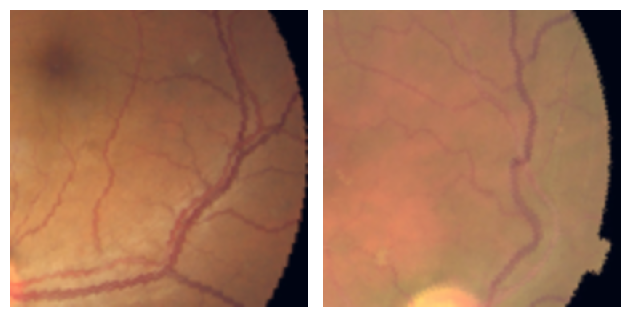

Feature map: 473
Label: 2


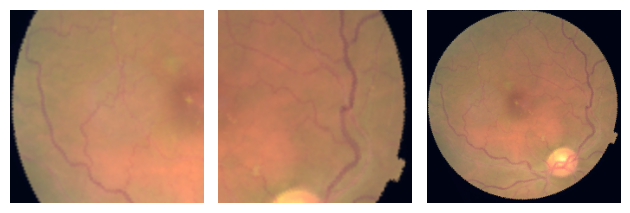

2
Feature map: 655
Label: 0


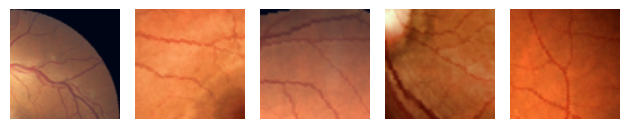

Feature map: 1234
Label: 0


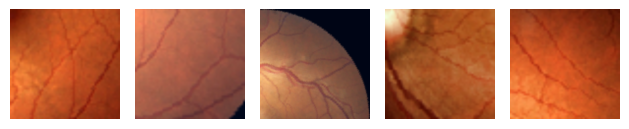

Feature map: 1846
Label: 0


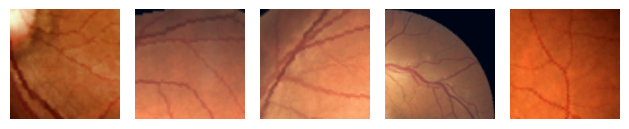

Feature map: 1591
Label: 0


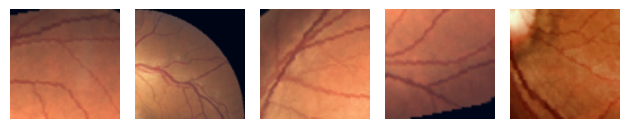

Feature map: 189
Label: 0


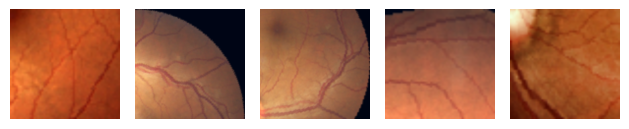

In [11]:
# visualize all cluster 
vis_labels = [i for i in range(num_cluster)]
num_vis = 5             # number of examples to visualize
for vis_label in vis_labels:
    print(vis_label)
    FW.visualize_cluster_concept_vectors(cluster_layer, vis_label, dict_labels, num_vis, num_top_images=5)

We can trace back what concepts at lower layer have strong impacts on the concept of upper layer.
The dictionary have the structure: {lower_layer_concept_id: score}.

Feature map: 1846
Label: 1


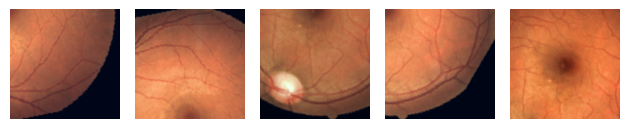

=========layer:8===========
Top concepts of 0 are: {4: 5.797230372778287}
------Layer: 8 cluster_label: 4 ------
Feature map: 1234
Label: 0


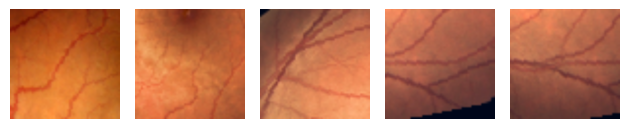

=========layer:7===========
Top concepts of 4 are: {8: 5.56310557947212}
------Layer: 7 cluster_label: 8 ------
Feature map: 701
Label: 1


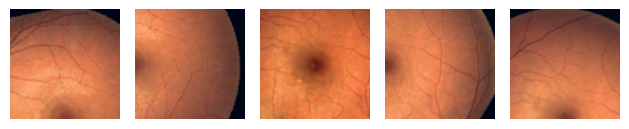

In [12]:
list_num_cluster = [10, 5, 3]   # number of cluster per layer
concept_id = 0                  # id of concept to visualize
end = 9                         # layer of the concept 
start = 7                       # trace back to start layer
num_top_concepts= 1             # number of top concepts at previous layer
num_top_vecs = 10               # number of representation vectors for each concept
specify_cluster = True          # whether to specify the number of cluster - if false then this function will self-determine

visualize_chain_of_concepts(
    FW, 
    concept_id, 
    start, 
    end, 
    num_top_concepts, 
    list_num_cluster,
    specify_cluster,
    num_top_vecs = num_top_vecs,
)

Here, we can visualize what are the critical neurons of a target neuron.

In [14]:
'''
For a specific neuron, we can find the critical neurons that contribute to the activation of the target neuron.
'''

fm = 425
layer = 7
label = 0
num_show = 5
print("==================")
print("Target neuron:", fm)
print("==================")
crit_fms = FW.get_critical_neurons(layer, fm)
FW.visualize_top_images(layer, fm, num_top_imgs=num_show, label = label)

print("==================")
print("List critical neuron:", crit_fms)
print("==================")
count = 0
score_dict = crit_fms[label]
for cfm, score in score_dict.items():
    if count == 3:
        break
    count += 1
    print("===============")
    print("Critical neuron:", cfm)
    print("Score:", score)
    print("===============")
    FW.visualize_top_images(layer-1, cfm, num_top_imgs=num_show)

Target neuron: 425


ValueError: 425 is not a critical neuron at layer 7